In [10]:
%pip install scipy statsmodels matplotlib

Note: you may need to restart the kernel to use updated packages.


In [11]:
import os
if os.path.basename(os.getcwd()) == "Notebooks":
    os.chdir("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

df = pd.read_csv("Data/Clean/saas_clean.csv")
df.columns = [c.replace(" ", "_") for c in df.columns]
tier_order = ['0%','1-10%','11-20%','21-30%','31-40%','40%+']
df['Discount_Tier'] = pd.Categorical(df['Discount_Tier'], categories=tier_order, ordered=True)
print(os.getcwd(), df.shape)

C:\Saas-Sales-Profitability (9994, 24)


In [12]:
rho, p = stats.spearmanr(df['Discount'], df['Margin'])
print("Spearman rho:", round(rho,3), "| p-value:", p)

Spearman rho: -0.645 | p-value: 0.0


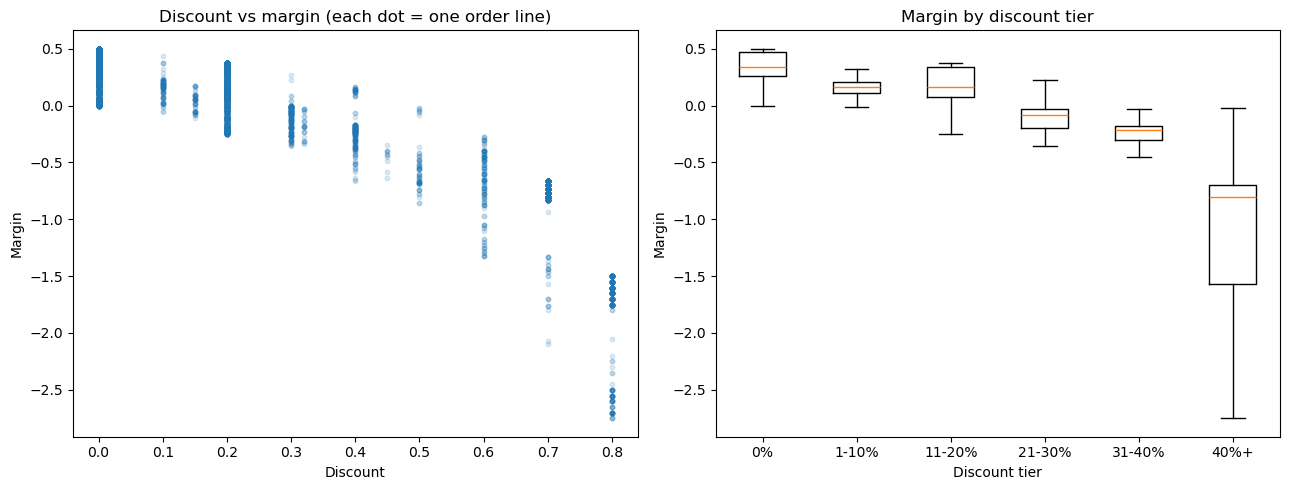

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13,5))
ax[0].scatter(df['Discount'], df['Margin'], alpha=0.15, s=10)
ax[0].set_xlabel("Discount"); ax[0].set_ylabel("Margin")
ax[0].set_title("Discount vs margin (each dot = one order line)")
groups = [df.loc[df['Discount_Tier']==t, 'Margin'] for t in tier_order]
ax[1].boxplot(groups, showfliers=False)
ax[1].set_xticks(range(1,7)); ax[1].set_xticklabels(tier_order)
ax[1].set_xlabel("Discount tier"); ax[1].set_ylabel("Margin")
ax[1].set_title("Margin by discount tier")
plt.tight_layout()
plt.savefig("Images/discount_vs_margin.png", dpi=150)
plt.show()

In [14]:
h, p = stats.kruskal(*groups)
print("Kruskal-Wallis H:", round(h,1), "| p-value:", p)
print(df.groupby('Discount_Tier', observed=True)['Margin'].median().round(3))

Kruskal-Wallis H: 4694.5 | p-value: 0.0
Discount_Tier
0%        0.340
1-10%     0.167
11-20%    0.162
21-30%   -0.086
31-40%   -0.217
40%+     -0.800
Name: Margin, dtype: float64


In [15]:
low = df.loc[df['Discount'] <= 0.10, 'Margin']
high = df.loc[df['Discount'] >= 0.30, 'Margin']
u, p = stats.mannwhitneyu(low, high, alternative='two-sided')
print("n low:", len(low), "| n high:", len(high))
print("Median margin, low:", round(low.median(),3), "| high:", round(high.median(),3))
print("Median difference (points):", round((low.median()-high.median())*100,1))
print("Rank-biserial effect size:", round(2*u/(len(low)*len(high))-1,3))
print("p-value:", p)

n low: 4892 | n high: 1393
Median margin, low: 0.33 | high: -0.7
Median difference (points): 103.0
Rank-biserial effect size: 0.995
p-value: 0.0


In [16]:
m1 = smf.ols("Margin ~ Discount + C(Segment) + C(Product)", data=df).fit(cov_type="HC3")
print("+10 points of discount changes margin by (points):", round(m1.params['Discount']*10, 1))
print("R-squared:", round(m1.rsquared,3))
print(m1.summary().tables[1])

+10 points of discount changes margin by (points): -20.4
R-squared: 0.798
                                               coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------
Intercept                                    0.6456      0.023     28.122      0.000       0.601       0.691
C(Segment)[T.SMB]                           -0.0015      0.006     -0.279      0.780      -0.012       0.009
C(Segment)[T.Strategic]                      0.0061      0.006      1.014      0.311      -0.006       0.018
C(Product)[T.Big Ol Database]               -0.0954      0.032     -3.001      0.003      -0.158      -0.033
C(Product)[T.ChatBot Plugin]                -0.2423      0.023    -10.592      0.000      -0.287      -0.197
C(Product)[T.ContactMatcher]                -0.1184      0.023     -5.121      0.000      -0.164      -0.073
C(Product)[T.Data Smasher]                  -0.2686   

In [17]:
d2 = df[df['Discount'] <= 0.20]
m2 = smf.ols("Margin ~ Discount + C(Segment) + C(Product)", data=d2).fit(cov_type="HC3")
print("Rows:", len(d2))
print("+10 points of discount changes margin by (points):", round(m2.params['Discount']*10, 1))
print("R-squared:", round(m2.rsquared,3))

Rows: 8601
+10 points of discount changes margin by (points): -8.6
R-squared: 0.546


In [18]:
df['Band'] = np.where(df['Discount'] > 0.20, 'Above 20%', '20% or less')
print(df.pivot_table(index='Product', columns='Band', values='Is_Loss', aggfunc=['mean','count']).round(2))

                                  mean                 count          
Band                       20% or less Above 20% 20% or less Above 20%
Product                                                               
Alchemy                           0.00      0.00        59.0       9.0
Big Ol Database                   0.00      0.83        62.0      53.0
ChatBot Plugin                    0.00       NaN       796.0       NaN
ContactMatcher                    0.03      0.99      1053.0     789.0
Data Smasher                      0.12       NaN       775.0       NaN
FinanceHub                        0.11      0.94       823.0     158.0
Marketing Suite                   0.25      0.99       158.0      70.0
Marketing Suite - Gold            0.19       NaN       846.0       NaN
OneView                           0.00      1.00       399.0      67.0
SaaS Connector Pack               0.04      1.00       819.0     138.0
SaaS Connector Pack - Gold        0.00       NaN       254.0       NaN
Site A

# 03 Statistics
## Findings
- Spearman correlation, discount vs margin: -0.65 (p < 0.001)
- Median margin: 0-10% discount = 33.0%, 30%+ discount = -70.0% (difference 103.0 points, rank-biserial effect size 1.00, p < 0.001)
- Regression (all data): +10 points of discount is associated with -20.4 points of margin (R-squared 0.80)
- Regression (discount up to 20%): +10 points of discount is associated with -8.6 points of margin (R-squared 0.55, 8601 rows)
- Above a 20% discount: 1,393 lines, 96.8% loss-making, profit -135k. At 20% or less: 8,601 lines, 6.1% loss-making, profit 422k.
- Limits: public synthetic sample, so these are associations, not proof of cause. The discount effect steepens at higher discounts (about -8.6 points of margin per +10 points up to 20%; larger above). Above 20%, losses are concentrated in a few products (ContactMatcher is 789 of 1,393 lines). Tiers 1-10%, 21-30% and 31-40% have small samples.